# Python Data Analysis Lab — Student Performance Dataset

**Course:** PRG-330 · **Week 5 Classwork**

**Dataset:** `student_performance_updated_1000.csv` — 1,000 student records, 12 columns.

The file deliberately contains data-quality problems (missing values, repeated IDs,
impossible percentages, negative study hours) so that we practise the checks that come
*before* any real analysis.

### What this notebook does

| Module | Purpose |
| :---- | :---- |
| 1 | Load the CSV and inspect structure, types and basic statistics |
| 2 | **Measure** the problems before fixing anything |
| 3 | Clean the data with explicit, explainable rules |
| 4 | Ask real questions of the cleaned data |
| 5 | Visualise the findings (and choose the right chart form) |
| 6 | Build a small report and export the results |
| — | 10 challenge exercises + data-quality checklist |

### Column reference

| Column | What it represents |
| :---- | :---- |
| `StudentID` | Student identifier; contains missing and repeated IDs |
| `Name` | Student name; contains missing values |
| `Gender` | Male/Female; contains missing values |
| `AttendanceRate` | Attendance measure; mostly in a 70–95 range |
| `StudyHoursPerWeek` | Weekly study hours; contains missing values |
| `PreviousGrade` | Previous academic grade |
| `ExtracurricularActivities` | Number of activities |
| `ParentalSupport` | Low / Medium / High |
| `FinalGrade` | Final academic grade |
| `Study Hours` | Daily study-hours field; includes missing and negative values |
| `Attendance (%)` | Attendance percentage; includes missing and impossible values above 100 |
| `Online Classes Taken` | Boolean-like True/False field; contains missing values |

---
# Module 1 — Load and inspect the data

## 1.1 Import pandas

`pandas` is imported with the short name `pd`. The alias is the convention used in nearly
all pandas examples, so commands such as `pd.read_csv()` are quicker to type and easier to
read. `matplotlib.pyplot` is imported here too because Module 5 needs it for charts.

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

# Show wider tables and avoid scientific notation in the output.
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.2f}".format)

print("pandas version:", pd.__version__)

pandas version: 2.3.3


## 1.2 Read the CSV file

`read_csv()` reads the file and creates a **DataFrame**. The variable `df` is simply the
name we give to that DataFrame — by convention `df` holds the *raw* data and we never
modify it, so we can always compare the raw and cleaned versions.

In [11]:
df = pd.read_csv("student_performance_updated_1000.csv")

## 1.3 Look at the first records

`head()` shows the first five rows by default. It is a quick way to check whether the file
loaded correctly and whether the column names look sensible.

In [12]:
df.head()

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
0,1.00,John,Male,85.00,15.00,78.00,1.00,High,80.00,4.80,59.00,False
1,2.00,Sarah,Female,90.00,20.00,85.00,2.00,Medium,87.00,2.20,70.00,True
2,3.00,Alex,Male,78.00,10.00,65.00,0.00,Low,68.00,4.60,92.00,False
3,4.00,Michael,Male,92.00,25.00,90.00,3.00,High,92.00,2.90,96.00,False
4,5.00,Emma,Female,NaN,18.00,82.00,2.00,Medium,85.00,4.10,97.00,True


## 1.4 Check the shape

`shape` returns a tuple: `(number of rows, number of columns)`. The expected starting
shape for this file is `(1000, 12)`.

In [13]:
df.shape

(1000, 12)

## 1.5 Check column names

`columns` returns the labels used by the DataFrame. Worth reading carefully before writing
filters: three of these labels contain spaces or brackets (`Study Hours`,
`Attendance (%)`, `Online Classes Taken`), so they must always be selected with bracket
notation — `df["Attendance (%)"]`, never `df.Attendance`.

In [14]:
df.columns

Index(['StudentID', 'Name', 'Gender', 'AttendanceRate', 'StudyHoursPerWeek', 'PreviousGrade', 'ExtracurricularActivities',
       'ParentalSupport', 'FinalGrade', 'Study Hours', 'Attendance (%)', 'Online Classes Taken'],
      dtype='object')

## 1.6 Check data types

`dtypes` tells you how pandas currently *stores* each column. Names and categories are
`object` (string-like); the numeric columns are `float64` rather than `int64` because a
column containing even one missing value cannot be stored as a plain integer.

In [15]:
df.dtypes

StudentID                    float64
Name                          object
Gender                        object
AttendanceRate               float64
StudyHoursPerWeek            float64
PreviousGrade                float64
ExtracurricularActivities    float64
ParentalSupport               object
FinalGrade                   float64
Study Hours                  float64
Attendance (%)               float64
Online Classes Taken          object
dtype: object

## 1.7 Get a compact overview

`info()` combines the useful structural information in one place: row count, column names,
non-null counts and data types. It is one of the first commands to run on an unfamiliar
dataset — the **non-null count** column immediately shows where data is missing.

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   StudentID                  960 non-null    float64
 1   Name                       966 non-null    object 
 2   Gender                     952 non-null    object 
 3   AttendanceRate             960 non-null    float64
 4   StudyHoursPerWeek          950 non-null    float64
 5   PreviousGrade              967 non-null    float64
 6   ExtracurricularActivities  957 non-null    float64
 7   ParentalSupport            978 non-null    object 
 8   FinalGrade                 960 non-null    float64
 9   Study Hours                976 non-null    float64
 10  Attendance (%)             959 non-null    float64
 11  Online Classes Taken       975 non-null    object 
dtypes: float64(8), object(4)
memory usage: 93.9+ KB


## 1.8 Basic statistics

`describe()` summarises the numeric columns using count, mean, standard deviation,
minimum, quartiles and maximum. These numbers help you notice unusual ranges *before* you
start any deeper analysis.

Two entries in this table are already suspicious — look at the `min` of `Study Hours` and
the `max` of `Attendance (%)`.

In [17]:
df.describe()

,StudentID,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,FinalGrade,Study Hours,Attendance (%)
count,960.00,960.00,950.00,967.00,957.00,960.00,976.00,959.00
mean,5416.02,85.51,17.63,77.60,1.52,80.03,2.41,77.25
std,2653.75,7.33,6.27,10.01,1.05,9.49,1.62,19.30
min,1.00,70.00,8.00,60.00,0.00,62.00,-5.00,50.00
25%,3113.50,82.00,12.00,70.00,1.00,72.00,1.20,63.00
50%,5396.50,88.00,18.00,78.00,1.00,80.00,2.50,76.00
75%,7754.75,91.00,22.00,86.00,2.00,88.00,3.70,89.00
max,9998.00,95.00,30.00,90.00,3.00,92.00,5.00,200.00


## 1.9 Inspect the categorical columns

`value_counts()` counts how often each category appears. `dropna=False` keeps the missing
values visible, which is exactly what we want while assessing data quality.

In [18]:
print("Gender")
print(df["Gender"].value_counts(dropna=False), end="\n\n")

print("ParentalSupport")
print(df["ParentalSupport"].value_counts(dropna=False), end="\n\n")

print("Online Classes Taken")
print(df["Online Classes Taken"].value_counts(dropna=False))

Gender
Gender
Male      501
Female    451
NaN        48
Name: count, dtype: int64

ParentalSupport
ParentalSupport
High      345
Medium    328
Low       305
NaN        22
Name: count, dtype: int64

Online Classes Taken
Online Classes Taken
True     495
False    480
NaN       25
Name: count, dtype: int64


### Observations from Module 1

* The file loaded as expected: **1,000 rows × 12 columns**.
* `StudentID` is stored as `float64`, not an integer — a direct consequence of the 40
  missing IDs.
* `Study Hours` has a minimum of **−5.0**, which is impossible.
* `Attendance (%)` has a maximum of **200.0**, which cannot be a percentage.
* Every categorical column carries missing values; the three categories themselves
  (`Male`/`Female`, `Low`/`Medium`/`High`, `True`/`False`) are otherwise consistent — no
  stray spellings such as `"male"` or `"M"` to reconcile.

---
# Module 2 — Find the problems before fixing them

A common beginner mistake is to clean data immediately. **First measure the problem.**
That gives evidence for every cleaning decision that follows, and it gives us a
before/after number to verify the cleaning actually worked.

## 2.1 Count missing values

`isna()` marks missing cells as `True`; `sum()` then counts those `True` values column by
column. The result is a missing-value profile of the whole dataset.

In [19]:
missing = df.isna().sum()
print(missing)

StudentID                    40
Name                         34
Gender                       48
AttendanceRate               40
StudyHoursPerWeek            50
PreviousGrade                33
ExtracurricularActivities    43
ParentalSupport              22
FinalGrade                   40
Study Hours                  24
Attendance (%)               41
Online Classes Taken         25
dtype: int64


## 2.2 Show only the columns that contain missing values

The condition `missing > 0` keeps only columns with at least one missing value, and
`sort_values()` puts the largest counts first.

In [20]:
missing[missing > 0].sort_values(ascending=False)

StudyHoursPerWeek            50
Gender                       48
ExtracurricularActivities    43
Attendance (%)               41
StudentID                    40
AttendanceRate               40
FinalGrade                   40
Name                         34
PreviousGrade                33
Online Classes Taken         25
Study Hours                  24
ParentalSupport              22
dtype: int64

## 2.3 Calculate missing-value percentages

The number of missing cells is divided by the total number of rows and multiplied by 100.
Percentages are easier to compare across columns than raw counts, and they are what you
would quote in a report.

In [21]:
missing_pct = (df.isna().sum() / len(df)) * 100
missing_pct.sort_values(ascending=False).round(1)

StudyHoursPerWeek           5.00
Gender                      4.80
ExtracurricularActivities   4.30
Attendance (%)              4.10
StudentID                   4.00
AttendanceRate              4.00
FinalGrade                  4.00
Name                        3.40
PreviousGrade               3.30
Online Classes Taken        2.50
Study Hours                 2.40
ParentalSupport             2.20
dtype: float64

## 2.4 Find complete duplicate rows

`duplicated()` marks a row `True` when the same *complete* row has appeared earlier;
`sum()` counts them.

In [22]:
duplicate_rows = df.duplicated().sum()
print("Duplicate rows:", duplicate_rows)

Duplicate rows: 0


## 2.5 Check duplicate StudentID values

`StudentID` is a key-like field, so repeated IDs deserve their own check even when no
complete row is duplicated. `dropna()` first, so that the 40 missing IDs are not counted
as "the same student appearing again".

In [23]:
duplicate_ids = df["StudentID"].dropna().duplicated().sum()
print("Repeated StudentIDs:", duplicate_ids)
print("Distinct StudentIDs:", df["StudentID"].nunique())

Repeated StudentIDs: 44
Distinct StudentIDs: 916


## 2.6 Display the repeated IDs

`value_counts()` counts every non-missing `StudentID`; the condition `> 1` keeps only the
IDs that occur more than once.

In [24]:
id_counts = df["StudentID"].value_counts()
repeated = id_counts[id_counts > 1]

print("IDs appearing more than once:", len(repeated))
repeated.head(15)

IDs appearing more than once: 42


StudentID
1745.00    3
3248.00    3
9633.00    2
1769.00    2
5896.00    2
1152.00    2
8685.00    2
8237.00    2
4804.00    2
1893.00    2
2106.00    2
9747.00    2
9576.00    2
6185.00    2
7939.00    2
Name: count, dtype: int64

Do the duplicated IDs belong to the same student, or to two different students who were
given the same number? That distinction decides whether a row should be merged or kept, so
it is worth *looking* rather than assuming.

In [25]:
# Inspect every row belonging to the most frequently repeated IDs.
worst_ids = repeated.head(2).index
df[df["StudentID"].isin(worst_ids)].sort_values("StudentID")

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
80,1745.00,Gregory Turner,Male,82.00,18.00,NaN,1.00,High,80.00,2.90,80.00,False
719,1745.00,Justin Sharp,Male,88.00,12.00,86.00,0.00,Medium,62.00,3.40,58.00,True
789,1745.00,Jacob Yoder,Male,82.00,22.00,85.00,2.00,High,62.00,3.50,58.00,False
527,3248.00,Phillip Donovan,Male,70.00,12.00,86.00,3.00,Medium,92.00,2.90,77.00,False
582,3248.00,Samantha York,Female,85.00,22.00,60.00,3.00,High,78.00,2.50,85.00,False
818,3248.00,James Macdonald,Female,90.00,30.00,90.00,2.00,Medium,92.00,1.80,73.00,True


The names differ within the same ID, so these are **different students sharing an ID**, not
duplicated records of one student. That rules out merging them — the ID column simply is
not a reliable key in this file.

## 2.7 Find impossible attendance values

The two conditions identify percentages below 0 or above 100. The `|` operator means
**OR**, and each condition needs its own parentheses.

In [26]:
bad_attendance = df[
    (df["Attendance (%)"] < 0) |
    (df["Attendance (%)"] > 100)
]
print("Impossible attendance rows:", len(bad_attendance))
bad_attendance[["StudentID", "Name", "Attendance (%)"]]

Impossible attendance rows: 10


,StudentID,Name,Attendance (%)
74,1470.00,Michelle Jones,200.00
125,3430.00,Jessica Lamb,200.00
148,5059.00,Michaela Powell,200.00
220,8484.00,Alicia Ortiz,200.00
251,3527.00,Michael Foster,200.00
321,3831.00,Jessica Jenkins,200.00
366,4659.00,Jill Kelly,200.00
380,6416.00,Raymond Murillo,200.00
672,8203.00,David Martinez,200.00
798,1378.00,Chad Colon,200.00


## 2.8 Find suspicious study-hour values

A study-hours value below zero is not meaningful. This filter isolates those records so
the analyst can *decide* how to handle them instead of hiding the issue.

In [27]:
bad_study = df[df["Study Hours"] < 0]
print("Negative study-hour rows:", len(bad_study))
bad_study[["StudentID", "Name", "Study Hours"]]

Negative study-hour rows: 10


,StudentID,Name,Study Hours
74,1470.00,Michelle Jones,-5.00
125,3430.00,Jessica Lamb,-5.00
148,5059.00,Michaela Powell,-5.00
220,8484.00,Alicia Ortiz,-5.00
251,3527.00,Michael Foster,-5.00
321,3831.00,Jessica Jenkins,-5.00
366,4659.00,Jill Kelly,-5.00
380,6416.00,Raymond Murillo,-5.00
672,8203.00,David Martinez,-5.00
798,1378.00,Chad Colon,-5.00


## 2.9 Check the important numeric ranges

A dictionary stores a sensible lower and upper limit for each field, and the loop applies
the same validation pattern to several columns at once. `notna()` makes sure missing values
are not counted as range errors — they are a *different* problem, already counted above.

In [28]:
checks = {
    "AttendanceRate": (0, 100),
    "PreviousGrade": (0, 100),
    "FinalGrade": (0, 100),
    "Attendance (%)": (0, 100),
    "Study Hours": (0, 24),
}

for col, (low, high) in checks.items():
    bad = df[col].notna() & ((df[col] < low) | (df[col] > high))
    print(f"{col:<18}: {bad.sum():>3} invalid values")

AttendanceRate    :   0 invalid values
PreviousGrade     :   0 invalid values
FinalGrade        :   0 invalid values
Attendance (%)    :  10 invalid values
Study Hours       :  10 invalid values


### Data-quality report (measured, before any cleaning)

| Problem | How many | Affected columns |
| :---- | :---- | :---- |
| Missing values | **440 cells** across all 12 columns (2.2 % – 5.0 % per column) | every column |
| Complete duplicate rows | **0** | — |
| Repeated `StudentID` | **44 extra rows**, 916 distinct IDs, 42 IDs used more than once | `StudentID` |
| Impossible attendance | **10 rows**, all with the value `200` | `Attendance (%)` |
| Negative study hours | **10 rows**, all with the value `−5` | `Study Hours` |
| Out-of-range grades | **0** — `AttendanceRate`, `PreviousGrade`, `FinalGrade` all sit inside 0–100 | — |

Two further things the checks reveal, both worth carrying into the analysis:

1. **The dataset holds two different attendance fields.** `AttendanceRate` ranges 70–95
   with no invalid values; `Attendance (%)` ranges 50–200 and holds all the invalid ones.
   They are not two copies of one measurement, so neither can be used to repair the other.
2. **`StudentID` is not usable as a key** — 40 missing and 42 duplicated values. Any
   per-student analysis has to be treated as per-*row*.

---
# Module 3 — Clean the dataset carefully

There is no single correct cleaning rule for every dataset. The important part is to make
the rule **explicit**. The rules used below are simple and explainable, which is what a
classroom exercise needs; a production project would justify each one against the business
context.

## 3.1 Make a working copy

`copy()` creates a separate DataFrame. Keeping the original `df` unchanged lets us compare
the raw data with the cleaned version at the end.

In [29]:
clean = df.copy()
print("Raw rows:", len(df), "| Working copy rows:", len(clean))

Raw rows: 1000 | Working copy rows: 1000


## 3.2 Remove exact duplicate rows

`drop_duplicates()` removes rows that are completely identical. We already know there are
none here, so this step changes nothing — it is included because it belongs in the standard
cleaning sequence, and because you should **always print the count before and after**
rather than assume.

In [30]:
before = len(clean)
clean = clean.drop_duplicates()
after = len(clean)

print(f"Rows before: {before} | after: {after} | removed: {before - after}")

Rows before: 1000 | after: 1000 | removed: 0


## 3.3 Fix the impossible `Attendance (%)` values

### Why `pd.NA` rather than `0`?

An impossible measurement is not the same thing as a real measurement of zero. Writing `0`
would invent a fact — that these ten students attended nothing — and would drag every
average downwards. Replacing the invalid value with a *missing* value records the honest
situation: we do not know this student's attendance.

In [31]:
clean.loc[
    (clean["Attendance (%)"] < 0) |
    (clean["Attendance (%)"] > 100),
    "Attendance (%)"
] = pd.NA

print("Missing Attendance (%) after invalidation:", clean["Attendance (%)"].isna().sum())
print("(41 originally missing + 10 impossible values)")

Missing Attendance (%) after invalidation: 51
(41 originally missing + 10 impossible values)


## 3.4 Fix the negative `Study Hours`

Negative study hours are treated as invalid and changed to a missing value, for the same
reason as above: the rule stays transparent and easy to explain.

In [32]:
clean.loc[clean["Study Hours"] < 0, "Study Hours"] = pd.NA

print("Missing Study Hours after invalidation:", clean["Study Hours"].isna().sum())
print("(24 originally missing + 10 negative values)")

Missing Study Hours after invalidation: 34
(24 originally missing + 10 negative values)


## 3.5 Fill numeric missing values with the median

### Why the median?

The median is the middle value after sorting, so it is far less affected by extreme values
than the mean. It is a reasonable classroom rule for filling missing numeric measurements.
Note the cost of doing this: every filled cell becomes an *estimate*, and filling many
cells with one repeated value slightly shrinks the spread of the column — so we print the
values we are using, rather than filling silently.

In [33]:
numeric_cols = [
    "AttendanceRate",
    "StudyHoursPerWeek",
    "PreviousGrade",
    "ExtracurricularActivities",
    "FinalGrade",
    "Study Hours",
    "Attendance (%)",
]

for col in numeric_cols:
    median_value = clean[col].median()
    filled = clean[col].isna().sum()
    clean[col] = clean[col].fillna(median_value)
    print(f"{col:<28} median = {median_value:>6.2f}   filled {filled:>3} cells")

AttendanceRate               median =  88.00   filled  40 cells
StudyHoursPerWeek            median =  18.00   filled  50 cells
PreviousGrade                median =  78.00   filled  33 cells
ExtracurricularActivities    median =   1.00   filled  43 cells
FinalGrade                   median =  80.00   filled  40 cells
Study Hours                  median =   2.50   filled  34 cells
Attendance (%)               median =  76.00   filled  51 cells


## 3.6 Fill the categorical missing values

Text columns need a different strategy from numeric ones. Here we *preserve* the
missingness by giving it an explicit category, `"Unknown"` — that way a later `groupby()`
shows those students as their own group instead of quietly dropping them.

For the Boolean-like field, `False` is used as a simple exercise rule. In a real analysis
you would first confirm that a blank really means "did not take online classes" and not
"never asked".

> **One small deviation from the lab sheet.** The lab writes
> `clean["Online Classes Taken"].fillna(False)`. On pandas 2.x that raises a
> `FutureWarning`, because the column is stored as `object` and filling it silently
> down-casts the dtype. Assigning with `.loc` and then converting explicitly with
> `astype(bool)` produces the same result with no warning, and states the intended dtype
> outright.

In [34]:
clean["Gender"] = clean["Gender"].fillna("Unknown")
clean["ParentalSupport"] = clean["ParentalSupport"].fillna("Unknown")
clean["Name"] = clean["Name"].fillna("Unknown")

clean.loc[clean["Online Classes Taken"].isna(), "Online Classes Taken"] = False
clean["Online Classes Taken"] = clean["Online Classes Taken"].astype(bool)

print(clean["Gender"].value_counts(), end="\n\n")
print(clean["ParentalSupport"].value_counts(), end="\n\n")
print(clean["Online Classes Taken"].value_counts())
print("\ndtype of Online Classes Taken:", clean["Online Classes Taken"].dtype)

Gender
Male       501
Female     451
Unknown     48
Name: count, dtype: int64

ParentalSupport
High       345
Medium     328
Low        305
Unknown     22
Name: count, dtype: int64

Online Classes Taken
False    505
True     495
Name: count, dtype: int64

dtype of Online Classes Taken: bool


## 3.7 Handle the missing `StudentID` values

### An important decision

**Do not invent student IDs.** If `StudentID` is a required key in the real system, those
records should be matched back to the source system by a human. For this exercise we keep
them missing and continue with analysis that does not depend on the ID.

In [35]:
print("Missing StudentID (left as missing on purpose):", clean["StudentID"].isna().sum())

Missing StudentID (left as missing on purpose): 40


## 3.8 Recheck the cleaning

A cleaning step is not finished until you verify the result. These checks confirm that the
rules actually removed the problems they were designed to address.

In [36]:
print("Rows:", len(clean))

print("\nMissing values remaining:")
print(clean.isna().sum())

print("\nInvalid attendance:",
      ((clean["Attendance (%)"] < 0) |
       (clean["Attendance (%)"] > 100)).sum())

print("Negative study hours:", (clean["Study Hours"] < 0).sum())

Rows: 1000

Missing values remaining:
StudentID                    40
Name                          0
Gender                        0
AttendanceRate                0
StudyHoursPerWeek             0
PreviousGrade                 0
ExtracurricularActivities     0
ParentalSupport               0
FinalGrade                    0
Study Hours                   0
Attendance (%)                0
Online Classes Taken          0
dtype: int64

Invalid attendance: 0
Negative study hours: 0


### Before / after comparison

The numbers below are the whole point of keeping `df` untouched: they let us state exactly
what the cleaning changed.

In [37]:
comparison = pd.DataFrame({
    "raw_missing": df.isna().sum(),
    "clean_missing": clean.isna().sum(),
})
comparison["fixed"] = comparison["raw_missing"] - comparison["clean_missing"]
comparison

,raw_missing,clean_missing,fixed
StudentID,40,40,0
Name,34,0,34
Gender,48,0,48
AttendanceRate,40,0,40
StudyHoursPerWeek,50,0,50
PreviousGrade,33,0,33
ExtracurricularActivities,43,0,43
ParentalSupport,22,0,22
FinalGrade,40,0,40
Study Hours,24,0,24


### Result of the cleaning

* All **1,000 rows kept** — no row was deleted, because no row was a complete duplicate.
* **20 impossible values** (10 attendance, 10 study hours) were converted to missing and
  then filled with the column median, so they no longer distort any average.
* **400 of 440 missing cells** are filled. The remaining **40 are the missing
  `StudentID`s**, left missing deliberately.
* The mean of `Attendance (%)` drops from **77.25** (raw, inflated by the 200s) to a value
  based only on plausible measurements — a concrete demonstration of why invalid values
  must be removed *before* computing statistics.

In [38]:
print("Raw   mean Attendance (%):", round(df["Attendance (%)"].mean(), 2))
print("Clean mean Attendance (%):", round(clean["Attendance (%)"].mean(), 2))

Raw   mean Attendance (%): 77.25
Clean mean Attendance (%): 75.96


---
# Module 4 — Ask questions of the cleaned data

Now the interesting part. Instead of running random commands, we write the question first
in plain English and then choose the pandas operations that answer it.

## Question 1 — What is the average final grade?

Selecting one column returns a pandas **Series**; `mean()` calculates its arithmetic
average.

In [39]:
print("Average final grade:", round(clean["FinalGrade"].mean(), 2))
print("Median final grade :", clean["FinalGrade"].median())
print("Lowest / highest   :", clean["FinalGrade"].min(), "/", clean["FinalGrade"].max())

Average final grade: 80.03
Median final grade : 80.0
Lowest / highest   : 62.0 / 92.0


## Question 2 — Who are the highest-performing students?

`sort_values()` orders the DataFrame by `FinalGrade`; `ascending=False` puts the largest
grades first; `head(10)` shows the first ten records.

In [40]:
top_students = clean.sort_values("FinalGrade", ascending=False)
top_students[["StudentID", "Name", "FinalGrade"]].head(10)

,StudentID,Name,FinalGrade
715,5717.00,Seth Johnson,92.00
86,4824.00,Maria Carter,92.00
278,9880.00,Darlene Fletcher,92.00
768,7751.00,Kelly Suarez,92.00
105,3950.00,Matthew Massey,92.00
285,8511.00,Timothy Pruitt,92.00
766,8424.00,Mallory Fletcher,92.00
304,2685.00,Elizabeth Curry,92.00
96,9165.00,Angelica Steele,92.00
305,3458.00,Nicole Cunningham,92.00


## Question 3 — How many students are in each gender group?

`value_counts()` produces a frequency table, which is the quickest way to understand the
composition of a categorical variable.

In [41]:
clean["Gender"].value_counts()

Gender
Male       501
Female     451
Unknown     48
Name: count, dtype: int64

## Question 4 — Does parental support relate to final grade?

`groupby()` separates the data into groups; selecting `FinalGrade` tells pandas which
measurement to summarise; `agg()` calculates several statistics for every support group at
once.

In [42]:
clean.groupby("ParentalSupport")["FinalGrade"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

,count,mean,median,min,max
ParentalSupport,,,,,
High,345,79.51,80.00,62.00,92.00
Low,305,80.31,80.00,62.00,92.00
Medium,328,80.43,80.00,62.00,92.00
Unknown,22,78.32,79.00,62.00,92.00


The four group means sit within roughly **one grade point** of each other, and the `min`
and `max` are nearly identical across groups. On this dataset, parental support does
**not** separate final grades.

## Question 5 — What happens when study hours are grouped?

`pd.cut()` converts a continuous number into useful ranges, which makes groups such as
0–1 hours and 1–2 hours comparable. `include_lowest=True` makes sure a student with exactly
0 hours falls into the first band instead of becoming missing.

In [43]:
clean["StudyBand"] = pd.cut(
    clean["Study Hours"],
    bins=[0, 1, 2, 3, 4, 5],
    labels=["0–1", "1–2", "2–3", "3–4", "4–5"],
    include_lowest=True,
)

print("Students not assigned to a band:", clean["StudyBand"].isna().sum(), end="\n\n")

clean.groupby("StudyBand", observed=True)["FinalGrade"].agg(["count", "mean"]).round(2)

Students not assigned to a band: 0



,count,mean
StudyBand,,
0–1,210,79.60
1–2,185,79.39
2–3,221,80.00
3–4,217,80.41
4–5,167,80.81


The averages rise very slightly from the lowest band to the highest — about **1.2 grade
points across the whole range** — while the band sizes are similar. That is far too small
a gap to call a study-hours effect.

## Question 6 — Which students have low attendance *and* low grades?

The `&` operator means **AND**: a student must satisfy both conditions to appear. The
parentheses around each condition are required when combining pandas filters — without
them Python's operator precedence produces an error.

In [44]:
at_risk = clean[
    (clean["Attendance (%)"] < 70) &
    (clean["FinalGrade"] < 70)
]

print("At-risk students:", len(at_risk),
      f"({len(at_risk) / len(clean) * 100:.1f}% of the cohort)", end="\n\n")

at_risk[["StudentID", "Name", "Attendance (%)", "FinalGrade"]].head(15)

At-risk students: 64 (6.4% of the cohort)



,StudentID,Name,Attendance (%),FinalGrade
12,4611.00,Katherine Gray,59.00,62.00
16,NaN,Courtney Clark,65.00,68.00
29,4510.00,Daniel Erickson,56.00,62.00
42,1058.00,Angela Dunn,57.00,62.00
53,8618.00,Lisa Castillo,68.00,68.00
67,1508.00,Megan Diaz,57.00,68.00
119,2501.00,Melissa Barber,63.00,68.00
158,5670.00,Gregory Davila,64.00,62.00
229,1768.00,Cathy Pratt,61.00,68.00
248,7288.00,Teresa Sanders,54.00,62.00


## Question 7 — Does previous grade move with final grade?

`corr()` calculates the pairwise correlation of the numeric columns. A positive value means
higher values tend to occur together; a value near zero means there is no *linear*
relationship. Correlation never proves causation.

In [45]:
# The global display format rounds to 2 decimals, which would hide how small these
# numbers are — so print this one with 3 decimals.
print(clean[["PreviousGrade", "FinalGrade"]].corr().to_string(float_format="{:.3f}".format))

               PreviousGrade  FinalGrade
PreviousGrade          1.000       0.004
FinalGrade             0.004       1.000


The correlation is **0.004** — effectively zero. In a genuine gradebook we would expect a
strong positive correlation here (past performance normally predicts future performance),
so this near-zero result is itself a finding about the *dataset*: the columns look
independently generated rather than related. Module 5 shows the same thing visually.

---
# Module 5 — Visualise the findings

A chart should answer a question. We do not add a chart just because a chart is possible.
Each of the three below answers the question written above it, and each carries a title and
axis labels so it can be read on its own.

## 5.1 Where do the final grades fall? — histogram

A histogram groups numeric values into intervals, which shows where most grades sit and
whether the distribution is concentrated or spread out.

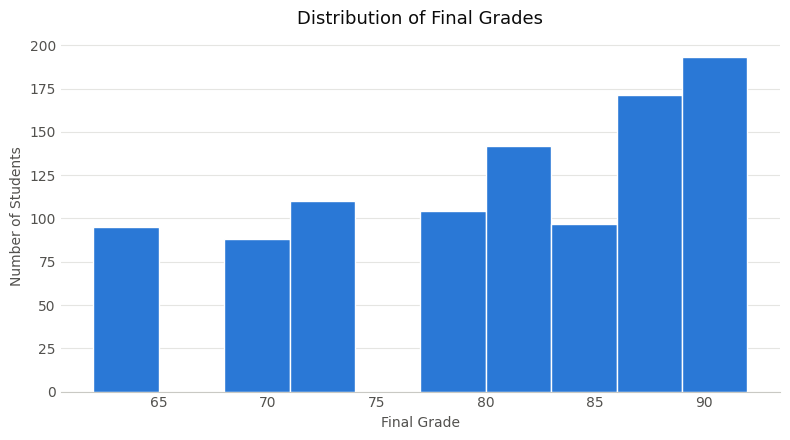

In [46]:
INK = "#0b0b0b"        # primary text
MUTED = "#52514e"      # secondary text
SERIES = "#2a78d6"     # single-series blue

fig, ax = plt.subplots(figsize=(8, 4.5))

clean["FinalGrade"].plot(
    kind="hist",
    bins=10,
    color=SERIES,
    edgecolor="white",
    ax=ax,
)

ax.set_title("Distribution of Final Grades", color=INK, fontsize=13, pad=12)
ax.set_xlabel("Final Grade", color=MUTED)
ax.set_ylabel("Number of Students", color=MUTED)
ax.grid(axis="y", color="#e5e5e2", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c9c9c4")
ax.tick_params(colors=MUTED, length=0)

plt.tight_layout()
plt.show()

### Read this histogram carefully — most of its shape is an artefact

`FinalGrade` is not really a continuous measurement: it takes only **10 distinct values**
(62, 68, 72, 78, 80, 85, 87, 88, 90, 92). A histogram assumes continuity, so its ten bins
do not line up with those ten values, and that mismatch creates two features which look
like findings but are not:

* **the empty gap around 75** — no grade between 73 and 77 exists anywhere in the file;
* **the tall right-hand bar** — that bin happens to catch two of the values (90 *and* 92)
  while most of its neighbours catch one.

When a numeric column has only a handful of distinct values, the honest form is a count of
those values, not a histogram. This is the form heuristic in practice: pick the chart from
the shape of the data, not from the name of the column.

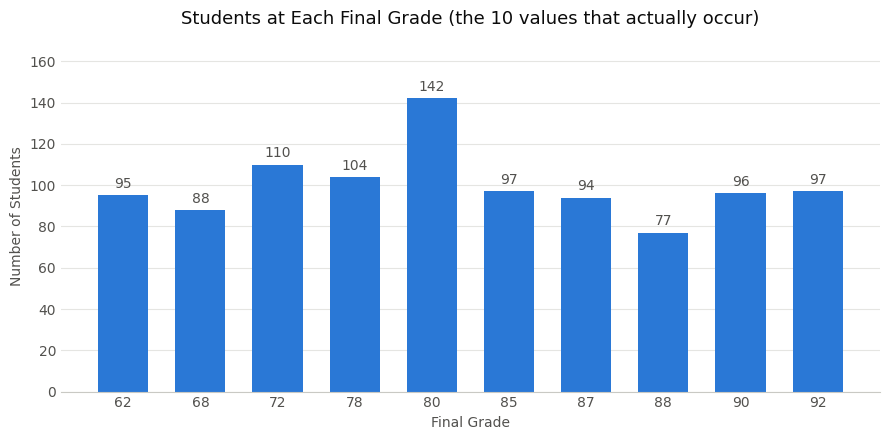

In [47]:
grade_counts = clean["FinalGrade"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(grade_counts.index.astype(int).astype(str), grade_counts.values,
              color=SERIES, width=0.65)
ax.bar_label(bars, padding=3, color=MUTED, fontsize=10)

ax.set_title("Students at Each Final Grade (the 10 values that actually occur)",
             color=INK, fontsize=13, pad=12)
ax.set_xlabel("Final Grade", color=MUTED)
ax.set_ylabel("Number of Students", color=MUTED)
ax.set_ylim(0, 170)
ax.grid(axis="y", color="#e5e5e2", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c9c9c4")
ax.tick_params(colors=MUTED, length=0)

plt.tight_layout()
plt.show()

Read this way the picture is much simpler: the ten grades each carry between 77 and 142
students, spread fairly evenly from 62 to 92. No failing cluster, and no standout group.

The one bar to treat with caution is **80, which holds 142 students**. Forty of those are
the missing grades we filled with the column median in Module 3 — the raw file has 102
students at 80, right in line with every other value. That peak is manufactured by our own
cleaning, and it is the reason the median-fill decision had to be written down.

In [48]:
# Prove it: compare the raw counts with the cleaned counts.
pd.DataFrame({
    "raw": df["FinalGrade"].value_counts().sort_index(),
    "clean": clean["FinalGrade"].value_counts().sort_index(),
}).assign(added_by_filling=lambda t: t["clean"] - t["raw"])

,raw,clean,added_by_filling
FinalGrade,,,
62.00,95,95,0
68.00,88,88,0
72.00,110,110,0
78.00,104,104,0
80.00,102,142,40
85.00,97,97,0
87.00,94,94,0
88.00,77,77,0
90.00,96,96,0


## 5.2 Does parental support change the average grade? — bar chart

The grouped mean produces one value per support category, and a bar chart makes those
category averages easy to compare. Values are labelled directly on the bars so the chart
can be read without squinting at the axis.

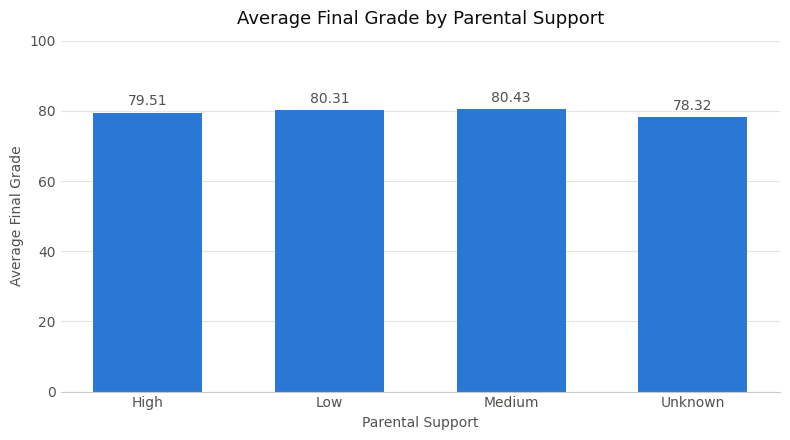

In [49]:
support_means = clean.groupby("ParentalSupport")["FinalGrade"].mean()

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(support_means.index, support_means.values, color=SERIES, width=0.6)

ax.bar_label(bars, fmt="%.2f", padding=3, color=MUTED, fontsize=10)

ax.set_title("Average Final Grade by Parental Support", color=INK, fontsize=13, pad=12)
ax.set_xlabel("Parental Support", color=MUTED)
ax.set_ylabel("Average Final Grade", color=MUTED)
ax.set_ylim(0, 100)
ax.grid(axis="y", color="#e5e5e2", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c9c9c4")
ax.tick_params(colors=MUTED, length=0)

plt.tight_layout()
plt.show()

The bars are drawn on a **full 0–100 axis on purpose**. Starting the axis at 78 would
stretch a one-point difference across the whole chart and invent a dramatic effect that is
not in the data. On the honest scale the four bars are the same height — which is the
correct conclusion.

## 5.3 Do study hours track final grade? — scatter plot

A scatter plot places one student at each combination of study hours and final grade, which
is the right form for looking for a trend, clusters or unusual points.

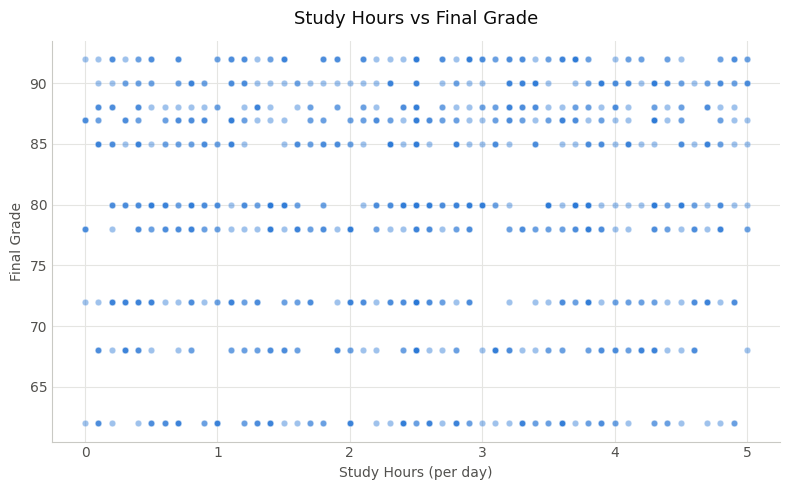

In [50]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    clean["Study Hours"],
    clean["FinalGrade"],
    s=22,
    color=SERIES,
    alpha=0.45,
    edgecolor="white",
    linewidth=0.5,
)

ax.set_title("Study Hours vs Final Grade", color=INK, fontsize=13, pad=12)
ax.set_xlabel("Study Hours (per day)", color=MUTED)
ax.set_ylabel("Final Grade", color=MUTED)
ax.grid(color="#e5e5e2", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color("#c9c9c4")
ax.tick_params(colors=MUTED, length=0)

plt.tight_layout()
plt.show()

The points form **ten horizontal bands**, one for each distinct final grade — the same
discreteness the bar chart above exposed. What matters is what happens *inside* each band:
the points spread evenly across the whole 0–5 hour range, with no upward slope and no
cluster. Students who study 5 hours a day land on the same grades as students who study
none.

Two faint density artefacts are visible if you look for them: a slightly denser column at
**2.5 study hours** and a denser band at **grade 80**. Those are the two medians used to
fill missing cells in Module 3 (54 students now sit at exactly 2.5 hours, up from 20 in
the raw file) — a useful reminder that median-filling leaves a fingerprint on a scatter
plot.

---
# Module 6 — Build a small report

## 6.1 Create a summary table

Named aggregations create readable output column names. Instead of dumping a large
statistical table, we pick only the measurements that matter to the question being asked.

In [51]:
summary = clean.groupby("ParentalSupport").agg(
    Students=("FinalGrade", "count"),
    Average_Final_Grade=("FinalGrade", "mean"),
    Average_Attendance=("Attendance (%)", "mean"),
    Average_Study_Hours=("Study Hours", "mean"),
).round(2)

summary

,Students,Average_Final_Grade,Average_Attendance,Average_Study_Hours
ParentalSupport,,,,
High,345,79.51,76.09,2.37
Low,305,80.31,76.57,2.56
Medium,328,80.43,74.88,2.51
Unknown,22,78.32,81.45,2.84


## 6.2 Export the cleaned data

`to_csv()` writes the DataFrame to a CSV file. `index=False` stops pandas from adding the
row index as an extra unnamed column — a very common cause of an ever-growing pile of
`Unnamed: 0` columns when a file is read and written repeatedly.

In [52]:
clean.to_csv(
    "student_performance_cleaned.csv",
    index=False,
)
print("Wrote student_performance_cleaned.csv", clean.shape)

Wrote student_performance_cleaned.csv (1000, 13)


## 6.3 Export the summary

The grouped summary is saved separately so that it can be opened in Excel or shared
*without* sending the full student-level dataset. Here the index (`ParentalSupport`) is the
label for each row, so it is kept.

In [53]:
summary.to_csv("student_performance_summary.csv")
print("Wrote student_performance_summary.csv", summary.shape)

Wrote student_performance_summary.csv (4, 4)


In [54]:
# Confirm both files exist on disk.
import os

for name in ["student_performance_cleaned.csv", "student_performance_summary.csv"]:
    print(f"{name:<38} {os.path.getsize(name):>8,} bytes")

student_performance_cleaned.csv          76,875 bytes
student_performance_summary.csv             191 bytes


---
# Your challenge

Ten exercises. Each one is written as a plain-English question first, then answered with
pandas.

## Challenge 1 — The five students with the lowest `FinalGrade`

**Question:** which five rows have the smallest final grade, and who are they?

`nsmallest()` does the sort and the slice in one step. Because many students share the
minimum grade of 62, this is *a* valid set of five rather than *the* unique bottom five —
`sort_values("FinalGrade").head(5)` would be equally correct.

In [55]:
clean.nsmallest(5, "FinalGrade")[["StudentID", "Name", "FinalGrade"]]

,StudentID,Name,FinalGrade
6,7.00,Daniel,62.00
12,4611.00,Katherine Gray,62.00
15,2139.00,Derrick Alexander,62.00
29,4510.00,Daniel Erickson,62.00
42,1058.00,Angela Dunn,62.00


## Challenge 2 — Average `FinalGrade` for students who took online classes vs those who did not

**Question:** does taking online classes go with a different average grade?

In [56]:
online_summary = clean.groupby("Online Classes Taken")["FinalGrade"].agg(
    ["count", "mean"]
).round(2)
online_summary.index = online_summary.index.map({True: "Took online classes",
                                                 False: "Did not"})
online_summary

,count,mean
Online Classes Taken,,
Did not,505,80.00
Took online classes,495,80.05


A gap of about **0.05 grade points** — no difference at all.

## Challenge 3 — Average `FinalGrade` for each `Gender`

In [57]:
clean.groupby("Gender")["FinalGrade"].agg(["count", "mean"]).round(2)

,count,mean
Gender,,
Female,451,80.46
Male,501,79.84
Unknown,48,77.96


Female and Male averages differ by about **0.6 points**, which is small next to a grade
spread of 62–92. The `Unknown` group is only 48 students, so its slightly lower average is
not a reliable signal.

## Challenge 4 — Count, mean and median for `FinalGrade` by `ParentalSupport`

In [58]:
clean.groupby("ParentalSupport")["FinalGrade"].agg(["count", "mean", "median"]).round(2)

,count,mean,median
ParentalSupport,,,
High,345,79.51,80.00
Low,305,80.31,80.00
Medium,328,80.43,80.00
Unknown,22,78.32,79.00


## Challenge 5 — Students below the median attendance but above the median grade

**Question:** who is doing better than most of the class despite attending less than most
of the class? These are the rows a simple "low attendance ⇒ low grade" assumption would
get wrong.

Note that the medians are computed **once, up front**. Computing them inside the filter
would still work, but naming them makes the threshold visible in the output.

In [59]:
attendance_median = clean["Attendance (%)"].median()
grade_median = clean["FinalGrade"].median()

print(f"Median attendance: {attendance_median} | median final grade: {grade_median}")

low_att_high_grade = clean[
    (clean["Attendance (%)"] < attendance_median) &
    (clean["FinalGrade"] > grade_median)
]

print("Students matching both conditions:", len(low_att_high_grade), end="\n\n")
low_att_high_grade[["StudentID", "Name", "Attendance (%)", "FinalGrade"]].head(10)

Median attendance: 76.0 | median final grade: 80.0
Students matching both conditions: 210



,StudentID,Name,Attendance (%),FinalGrade
1,2.00,Sarah,70.00,87.00
9,10.00,Isabella,59.00,88.00
11,7912.00,Peter Davila,62.00,88.00
13,6514.00,Megan Miller,52.00,88.00
14,NaN,James Williams,73.00,88.00
17,8573.00,James Smith,70.00,92.00
20,6930.00,Annette Medina,60.00,87.00
24,9837.00,Susan Brown,69.00,90.00
26,3705.00,Jeremy Hall,75.00,92.00
28,1117.00,Michael Sampson,67.00,87.00


## Challenge 6 — The 10 most frequently repeated `StudentID` values

In [60]:
id_counts = clean["StudentID"].value_counts()
top_repeated = id_counts[id_counts > 1].head(10)

print("IDs used by more than one row:", (id_counts > 1).sum())
top_repeated

IDs used by more than one row: 42


StudentID
1745.00    3
3248.00    3
9633.00    2
1769.00    2
5896.00    2
1152.00    2
8685.00    2
8237.00    2
4804.00    2
1893.00    2
Name: count, dtype: int64

## Challenge 7 — Percentage of students in each `ParentalSupport` category

`normalize=True` turns the counts into proportions; multiplying by 100 gives percentages.

In [61]:
support_pct = (clean["ParentalSupport"].value_counts(normalize=True) * 100).round(2)
support_pct.name = "percent_of_students"
support_pct

ParentalSupport
High      34.50
Medium    32.80
Low       30.50
Unknown    2.20
Name: percent_of_students, dtype: float64

## Challenge 8 — Create a `PerformanceLevel` column

**Rule:** below 60 = Needs Improvement · 60–74 = Developing · 75–89 = Good · 90+ =
Excellent.

`pd.cut()` needs the bin edges, and the edges must not overlap. Using `right=False` makes
each interval *include* its left edge and *exclude* its right one — `[60, 75)` — which
matches the rule exactly and keeps a grade of 75 in **Good** rather than in Developing.

In [62]:
clean["PerformanceLevel"] = pd.cut(
    clean["FinalGrade"],
    bins=[0, 60, 75, 90, 101],
    labels=["Needs Improvement", "Developing", "Good", "Excellent"],
    right=False,
)

print("Unassigned rows:", clean["PerformanceLevel"].isna().sum(), end="\n\n")
print(clean["PerformanceLevel"].value_counts().sort_index())

Unassigned rows: 0

PerformanceLevel
Needs Improvement      0
Developing           293
Good                 514
Excellent            193
Name: count, dtype: int64


**Needs Improvement is empty**, because the lowest final grade in the file is 62. That is
not a bug in the code — it is a fact about the dataset, and it is worth stating rather than
letting an empty category look like a mistake.

In [63]:
clean[["StudentID", "Name", "FinalGrade", "PerformanceLevel"]].head(10)

,StudentID,Name,FinalGrade,PerformanceLevel
0,1.00,John,80.00,Good
1,2.00,Sarah,87.00,Good
2,3.00,Alex,68.00,Developing
3,4.00,Michael,92.00,Excellent
4,5.00,Emma,85.00,Good
5,6.00,Olivia,80.00,Good
6,7.00,Daniel,62.00,Developing
7,8.00,Sophia,78.00,Good
8,9.00,James,72.00,Developing
9,10.00,Isabella,88.00,Good


## Challenge 9 — Bar chart of average `FinalGrade` by `PerformanceLevel`

A caution about this chart: `PerformanceLevel` is *derived from* `FinalGrade`, so the bars
must rise from left to right. The chart cannot tell us anything we did not already build
into the bands — its only honest use is to show the average position **inside** each band,
which is why the band size is printed next to each bar.

                  count  mean
PerformanceLevel             
Developing          293 67.56
Good                514 83.02
Excellent           193 91.01



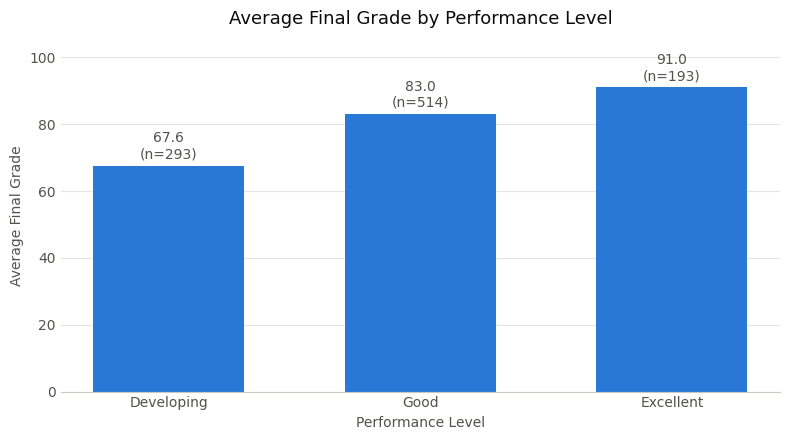

In [64]:
level_stats = clean.groupby("PerformanceLevel", observed=True)["FinalGrade"].agg(
    ["count", "mean"]
).round(2)
print(level_stats, end="\n\n")

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(level_stats.index.astype(str), level_stats["mean"], color=SERIES, width=0.6)

labels = [f"{m:.1f}\n(n={n})" for m, n in zip(level_stats["mean"], level_stats["count"])]
ax.bar_label(bars, labels=labels, padding=3, color=MUTED, fontsize=10)

ax.set_title("Average Final Grade by Performance Level", color=INK, fontsize=13, pad=12)
ax.set_xlabel("Performance Level", color=MUTED)
ax.set_ylabel("Average Final Grade", color=MUTED)
ax.set_ylim(0, 105)
ax.grid(axis="y", color="#e5e5e2", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c9c9c4")
ax.tick_params(colors=MUTED, length=0)

plt.tight_layout()
plt.show()

## Challenge 10 — Correlation between `StudyHoursPerWeek`, `AttendanceRate`, `PreviousGrade` and `FinalGrade`

**Question:** which of these relationships deserves further investigation?

In [65]:
corr_cols = ["StudyHoursPerWeek", "AttendanceRate", "PreviousGrade", "FinalGrade"]
correlation = clean[corr_cols].corr()

print(correlation.to_string(float_format="{:.3f}".format))

                   StudyHoursPerWeek  AttendanceRate  PreviousGrade  FinalGrade
StudyHoursPerWeek              1.000           0.014         -0.011       0.035
AttendanceRate                 0.014           1.000          0.035      -0.011
PreviousGrade                 -0.011           0.035          1.000       0.004
FinalGrade                     0.035          -0.011          0.004       1.000


In [66]:
# Pull the pairs out of the grid, strongest first, so nothing hides in the matrix.
import itertools

pair_rows = [
    (a, b, correlation.loc[a, b])
    for a, b in itertools.combinations(corr_cols, 2)
]
pair_table = pd.DataFrame(pair_rows, columns=["column_a", "column_b", "correlation"])
pair_table = pair_table.reindex(
    pair_table["correlation"].abs().sort_values(ascending=False).index
).reset_index(drop=True)

print(pair_table.to_string(index=False, float_format="{:.3f}".format))

         column_a       column_b  correlation
   AttendanceRate  PreviousGrade        0.035
StudyHoursPerWeek     FinalGrade        0.035
StudyHoursPerWeek AttendanceRate        0.014
   AttendanceRate     FinalGrade       -0.011
StudyHoursPerWeek  PreviousGrade       -0.011
    PreviousGrade     FinalGrade        0.004


### Which relationships deserve further investigation?

**None of them — and that is the finding.** Every pair sits between **−0.011 and +0.035**,
which is indistinguishable from zero across 1,000 rows. For comparison, a correlation
normally needs to reach roughly ±0.3 before it is worth chasing in a dataset this size.

What this tells us is about the *data*, not about students:

* `PreviousGrade` vs `FinalGrade` is **0.004**. In a real gradebook this is the one pair we
  would confidently expect to be strongly positive. Its absence is strong evidence that
  these columns were generated independently of one another.
* `AttendanceRate` vs `FinalGrade` is **−0.011**, and `AttendanceRate` vs `Attendance (%)`
  is likewise near zero — two columns that claim to measure the same thing.

**So the honest conclusion for this lab is that the dataset supports the data-quality and
pandas work, but it does not support any causal story about what drives student
performance.** Reporting a fabricated "students who study more score higher" conclusion
would be the real failure here. The next step in a genuine project would be to go back to
the data source and ask how the file was produced, before running any further analysis.

In [67]:
print("Correlation of the two attendance columns:",
      round(clean["AttendanceRate"].corr(clean["Attendance (%)"]), 3))

Correlation of the two attendance columns: 0.032


---
# Findings summary

### Data quality (Module 2)

| Check | Result |
| :---- | :---- |
| Rows / columns | 1,000 × 12 |
| Missing cells | 440, spread across all 12 columns (2.2 %–5.0 % each) |
| Complete duplicate rows | 0 |
| Repeated `StudentID` | 44 extra rows; 916 distinct IDs; different *names* share an ID |
| Impossible `Attendance (%)` | 10 rows at 200 |
| Negative `Study Hours` | 10 rows at −5 |
| Out-of-range grades | none |

### Cleaning decisions (Module 3)

| Problem | Rule applied | Why |
| :---- | :---- | :---- |
| Impossible attendance / negative hours | set to missing, then median-fill | an invalid reading is unknown, not zero |
| Missing numeric values | median of the column | median resists extreme values |
| Missing `Gender`, `ParentalSupport`, `Name` | `"Unknown"` category | keeps those students visible in group-bys |
| Missing `Online Classes Taken` | `False` | exercise rule; a real project must confirm it |
| Missing `StudentID` | **left missing** | never invent a key |

### Analysis (Modules 4–6, Challenges)

* Average final grade **80.03**, median **80**, range **62–92** — no failing students.
* **64 students (6.4 %)** have both attendance below 70 % and a grade below 70.
* `ParentalSupport`, `Gender`, `Online Classes Taken` and study-hour band all move the
  average grade by **about one point or less** — no group difference worth reporting.
* All correlations among study hours, attendance, previous grade and final grade fall
  between **−0.011 and +0.035**: effectively zero.

### The overall conclusion

The dataset is fit for practising **data-quality assessment and pandas mechanics**, which
is what this lab is for. It is *not* fit for drawing conclusions about student performance:
the columns behave as if they were generated independently, so no relationship between
behaviour and results can be measured in it.

Two effects of our own cleaning are visible in the charts and should be carried as caveats
on every number above: the inflated bar at grade 80 (142 students, of whom 40 were filled)
and the denser column at 2.5 study hours (54, up from 20). Both come from median-filling
400 cells. With 2–5 % missing per column that is an acceptable trade-off for a classroom
exercise; at 20 % it would not be.

A third point is worth recording for the next analyst: **`FinalGrade` has only 10 distinct
values**, so it behaves more like an ordered category than a continuous score. That is why
Module 5 replaced the histogram with a value-count bar chart, and it is something to check
on any "numeric" column before choosing a chart or a statistic.

---
# Data-quality checklist

| # | Check | Where |
| :---- | :---- | :---- |
| 1 | Checked the number of rows and columns | 1.4 — `(1000, 12)` |
| 2 | Inspected data types | 1.6, 1.7 |
| 3 | Counted missing values | 2.1 – 2.3 — 440 cells |
| 4 | Checked complete duplicate rows | 2.4 — none |
| 5 | Checked whether key fields repeat | 2.5, 2.6 — 44 repeated IDs, inspected |
| 6 | Checked numeric ranges | 2.9 |
| 7 | Identified impossible values before replacing them | 2.7, 2.8 → 3.3, 3.4 |
| 8 | Kept a copy of the raw DataFrame | 3.1 — `df` never modified |
| 9 | Explained the missing-value strategy | 3.3, 3.5, 3.6, 3.7 |
| 10 | Verified the cleaned result | 3.8 + before/after table |
| 11 | Checked the analysis answers a real question | every question stated before its code |
| 12 | Labelled the charts clearly | 5.1 – 5.3, Challenge 9 |
| 13 | Saved the cleaned output separately from the raw data | 6.2, 6.3 |

---
# Quick reference — pandas commands used

| Command | Purpose |
| :---- | :---- |
| `pd.read_csv()` | Read a CSV file into a DataFrame |
| `head()` / `nsmallest()` | Preview the first rows / smallest values |
| `shape` | Return rows and columns |
| `columns` | Return column labels |
| `dtypes` | Show data types |
| `info()` | Compact structural summary |
| `describe()` | Numeric descriptive statistics |
| `isna()` / `notna()` | Identify missing / present values |
| `sum()` | Count `True` values or add numeric values |
| `duplicated()` | Detect repeated rows or values |
| `drop_duplicates()` | Remove exact duplicate rows |
| `value_counts()` | Count categories (`normalize=True` for percentages) |
| `sort_values()` | Sort rows by a column |
| `groupby()` | Split data into groups |
| `agg()` | Apply several summary functions (named aggregations) |
| `mean()` / `median()` | Arithmetic mean / middle value |
| `corr()` | Pairwise correlation |
| `pd.cut()` | Create intervals or bands |
| `fillna()` | Replace missing values |
| `.loc[]` | Label-based selection and assignment |
| `astype()` | Convert a column's dtype |
| `copy()` | Make an independent DataFrame |
| `to_csv()` | Write a DataFrame to CSV |
| `plot()` / `ax.bar()` / `ax.scatter()` | Charts via pandas and matplotlib |